In [22]:
import torch
import os

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU non disponible")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [23]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    level = root.replace("/kaggle/input", "").count(os.sep)

    if level <= 4:
        print(root, "->", len(files), "fichiers")

/kaggle/input -> 0 fichiers
/kaggle/input/datasets -> 0 fichiers
/kaggle/input/datasets/chikhima -> 0 fichiers
/kaggle/input/datasets/chikhima/landcover-ai -> 0 fichiers
/kaggle/input/datasets/chikhima/landcover-ai/data -> 0 fichiers
/kaggle/input/datasets/adrianboguszewski -> 0 fichiers
/kaggle/input/datasets/adrianboguszewski/landcoverai -> 4 fichiers
/kaggle/input/datasets/adrianboguszewski/landcoverai/images -> 41 fichiers
/kaggle/input/datasets/adrianboguszewski/landcoverai/masks -> 41 fichiers


In [24]:
import os
import glob
import rasterio
import numpy as np

DATASET_PATH = (
    "/kaggle/input/datasets/chikhima/landcover-ai/"
    "data/processed/official/splits"
)

splits = ["train", "val", "test"]

for split in splits:
    image_dir = os.path.join(DATASET_PATH, split, "images")
    mask_dir = os.path.join(DATASET_PATH, split, "masks")

    images = sorted(glob.glob(os.path.join(image_dir, "*.tif")))
    masks = sorted(glob.glob(os.path.join(mask_dir, "*.tif")))

    image_names = {os.path.basename(f) for f in images}
    mask_names = {os.path.basename(f) for f in masks}

    print(f"\n=== {split.upper()} ===")
    print("Images :", len(images))
    print("Masks :", len(masks))
    print("Images sans masque :", len(image_names - mask_names))
    print("Masques sans image :", len(mask_names - image_names))

# Examiner un exemple
sample_image = images[0]
sample_mask = os.path.join(
    DATASET_PATH, "test", "masks",
    os.path.basename(sample_image)
)

with rasterio.open(sample_image) as src:
    image = src.read()
    print("\nImage shape :", image.shape)
    print("Image dtype :", image.dtype)

with rasterio.open(sample_mask) as src:
    mask = src.read(1)
    print("Mask shape :", mask.shape)
    print("Mask dtype :", mask.dtype)
    print("Classes présentes :", np.unique(mask))


=== TRAIN ===
Images : 7470
Masks : 7470
Images sans masque : 0
Masques sans image : 0

=== VAL ===
Images : 1602
Masks : 1602
Images sans masque : 0
Masques sans image : 0

=== TEST ===
Images : 1602
Masks : 1602
Images sans masque : 0
Masques sans image : 0

Image shape : (3, 512, 512)
Image dtype : uint8
Mask shape : (512, 512)
Mask dtype : uint8
Classes présentes : [2]


In [25]:
import os

PROJECT_DIR = "/kaggle/working/segmentation_landcover"

folders = [
    "src",
    "src/dataset",
    "src/models",
    "src/training"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

# Ajouter les fichiers __init__.py
for folder in folders:
    init_file = os.path.join(PROJECT_DIR, folder, "__init__.py")
    open(init_file, "a").close()

print("Arborescence créée.")

Arborescence créée.


In [26]:
import sys

sys.path.insert(0, PROJECT_DIR)

print("Project path:", PROJECT_DIR)

Project path: /kaggle/working/segmentation_landcover


In [30]:

%%writefile /kaggle/working/segmentation_landcover/src/dataset/landcover_dataset.py

import os
import rasterio
import torch
import numpy as np

from torch.utils.data import Dataset


class LandCoverDataset(Dataset):

    def __init__(self, root_dir, split):

        self.image_dir = os.path.join(root_dir, split, "images")
        self.mask_dir = os.path.join(root_dir, split, "masks")

        self.image_files = sorted([
            f for f in os.listdir(self.image_dir)
            if f.endswith(".tif")
        ])

        self.mask_files = sorted([
            f for f in os.listdir(self.mask_dir)
            if f.endswith(".tif")
        ])

        assert self.image_files == self.mask_files, \
            "Les images et les masques ne correspondent pas."

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, index):

        image_name = self.image_files[index]

        image_path = os.path.join(self.image_dir, image_name)
        mask_path = os.path.join(self.mask_dir, image_name)

        # Lire l'image RGB
        with rasterio.open(image_path) as src:
            image = src.read()

        # Lire le masque
        with rasterio.open(mask_path) as src:
            mask = src.read(1)

        # Normaliser l'image entre 0 et 1
        image = image.astype(np.float32) / 255.0

        # Conversion en tenseurs PyTorch
        image = torch.from_numpy(image)
        mask = torch.from_numpy(mask.astype(np.int64))

        return image, mask


Writing /kaggle/working/segmentation_landcover/src/dataset/landcover_dataset.py


In [31]:
from src.dataset.landcover_dataset import LandCoverDataset

In [32]:

from pathlib import Path

import numpy as np
import rasterio
import torch
from torch.utils.data import Dataset


class LandCoverDataset(Dataset):
    """
    Dataset PyTorch pour la segmentation sémantique
    du jeu de données LandCover.ai.

    Chaque élément contient :
    - Une image RGB normalisée.
    - Un masque avec les identifiants de classes 0 à 4.
    """

    def __init__(self, root_dir, split):
        self.root_dir = Path(root_dir) / split

        self.images_dir = self.root_dir / "images"
        self.masks_dir = self.root_dir / "masks"

        self.image_paths = sorted(
            self.images_dir.glob("*.tif")
        )

        if not self.image_paths:
            raise RuntimeError(
                f"Aucune image trouvée dans {self.images_dir}"
            )

        # Vérifier que chaque image possède son masque
        for image_path in self.image_paths:
            mask_path = self.masks_dir / image_path.name

            if not mask_path.exists():
                raise FileNotFoundError(
                    f"Masque manquant : {mask_path}"
                )

    def __len__(self):
        """Retourne le nombre d'images dans le dataset."""
        return len(self.image_paths)

    def __getitem__(self, index):
        """
        Charge une image et son masque à partir de leur index.
        """

        image_path = self.image_paths[index]
        mask_path = self.masks_dir / image_path.name

        # Lecture de l'image RGB
        with rasterio.open(image_path) as src:
            image = src.read([1, 2, 3])

        # Conversion CHW vers HWC
        image = np.transpose(image, (1, 2, 0))

        # Normalisation des valeurs entre 0 et 1
        image = image.astype(np.float32) / 255.0

        # Conversion HWC vers CHW
        image = np.transpose(image, (2, 0, 1))

        # Lecture du masque
        with rasterio.open(mask_path) as src:
            mask = src.read(1)

        # Vérifier les identifiants des classes
        if not np.isin(mask, [0, 1, 2, 3, 4]).all():
            raise ValueError(
                f"Identifiant de classe inconnu : {mask_path}"
            )

        # Conversion en tenseurs PyTorch
        image = torch.from_numpy(
            np.ascontiguousarray(image)
        )

        mask = torch.from_numpy(
            mask.astype(np.int64)
        )

        return image, mask
print("done")

done


In [41]:

import os
from torch.utils.data import DataLoader

from src.dataset.landcover_dataset import LandCoverDataset


DATASET_PATH = (
    "/kaggle/input/datasets/chikhima/landcover-ai/"
    "data/processed/official/splits"
)


def create_dataloaders(batch_size=4, num_workers=2):

    # Chargement des datasets
    train_dataset = LandCoverDataset(DATASET_PATH, "train")
    val_dataset = LandCoverDataset(DATASET_PATH, "val")
    test_dataset = LandCoverDataset(DATASET_PATH, "test")

    # Création des DataLoaders
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=True
    )

    return train_loader, val_loader, test_loader


if __name__ == "__main__":

    train_loader, val_loader, test_loader = create_dataloaders()

    print("Nombre de batches :")
    print("Train :", len(train_loader))
    print("Validation :", len(val_loader))
    print("Test :", len(test_loader))

    images, masks = next(iter(train_loader))

    print("\n=== TEST BATCH ===")
    print("Images :", images.shape)
    print("Masks :", masks.shape)
    print("Images dtype :", images.dtype)
    print("Masks dtype :", masks.dtype)
    print("Classes présentes :", masks.unique().tolist())


Nombre de batches :
Train : 1868
Validation : 401
Test : 401

=== TEST BATCH ===
Images : torch.Size([4, 3, 512, 512])
Masks : torch.Size([4, 512, 512])
Images dtype : torch.float32
Masks dtype : torch.int64
Classes présentes : [0, 2, 3, 4]


In [45]:
%%writefile /kaggle/working/segmentation_landcover/src/models/unet.py
import torch
import torch.nn as nn


class DoubleConv(nn.Module):
    """
    Deux convolutions successives :
    Conv2d -> BatchNorm -> ReLU
    Conv2d -> BatchNorm -> ReLU
    """

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class Encoder(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.conv = DoubleConv(in_channels, out_channels)

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

    def forward(self, x):

        features = self.conv(x)

        pooled = self.pool(features)

        return features, pooled


class Bottleneck(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.conv = DoubleConv(
            in_channels,
            out_channels
        )

    def forward(self, x):

        return self.conv(x)


class Decoder(nn.Module):

    def __init__(self, in_channels, skip_channels, out_channels):

        super().__init__()

        self.up = nn.ConvTranspose2d(
            in_channels,
            out_channels,
            kernel_size=2,
            stride=2
        )

        self.conv = DoubleConv(
            out_channels + skip_channels,
            out_channels
        )

    def forward(self, x, skip):

        # Augmenter la résolution
        x = self.up(x)

        # Concaténer avec les caractéristiques de l'Encoder
        x = torch.cat([x, skip], dim=1)

        # Raffiner les caractéristiques
        x = self.conv(x)

        return x

class UNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=5, base_channels=16):
        super().__init__()

        # Encoder
        self.enc1 = Encoder(in_channels, base_channels)
        self.enc2 = Encoder(base_channels, base_channels * 2)
        self.enc3 = Encoder(base_channels * 2, base_channels * 4)
        self.enc4 = Encoder(base_channels * 4, base_channels * 8)

        # Bottleneck
        self.bottleneck = Bottleneck(
            base_channels * 8,
            base_channels * 16
        )

        # Decoder
        self.dec4 = Decoder(
            base_channels * 16,
            base_channels * 8,
            base_channels * 8
        )

        self.dec3 = Decoder(
            base_channels * 8,
            base_channels * 4,
            base_channels * 4
        )

        self.dec2 = Decoder(
            base_channels * 4,
            base_channels * 2,
            base_channels * 2
        )

        self.dec1 = Decoder(
            base_channels * 2,
            base_channels,
            base_channels
        )

        # Classification de chaque pixel
        self.final_conv = nn.Conv2d(
            base_channels,
            num_classes,
            kernel_size=1
        )

    def forward(self, x):
        # Encoder
        skip1, x = self.enc1(x)
        skip2, x = self.enc2(x)
        skip3, x = self.enc3(x)
        skip4, x = self.enc4(x)

        # Bottleneck
        x = self.bottleneck(x)

        # Decoder
        x = self.dec4(x, skip4)
        x = self.dec3(x, skip3)
        x = self.dec2(x, skip2)
        x = self.dec1(x, skip1)

        # Output
        x = self.final_conv(x)

        return x

if __name__ == "__main__":
    model = UNet(
        in_channels=3,
        num_classes=5,
        base_channels=16
    )

    x = torch.randn(1, 3, 512, 512)

    with torch.no_grad():
        output = model(x)

    print("Input shape :", x.shape)
    print("Output shape :", output.shape)
    print("Nombre de paramètres :", sum(p.numel() for p in model.parameters()))


Writing /kaggle/working/segmentation_landcover/src/models/unet.py


In [48]:
%%writefile /kaggle/working/segmentation_landcover/src/training/losses.py

import torch
import torch.nn as nn


def get_loss_function():
    """
    Retourne la fonction de perte CrossEntropyLoss
    pour la segmentation sémantique.
    """
    return nn.CrossEntropyLoss()


if __name__ == "__main__":

    # Initialiser la fonction de perte
    criterion = get_loss_function()

    # Simuler les prédictions de U-Net
    # Batch = 2, Classes = 5, Hauteur = 512, Largeur = 512
    predictions = torch.randn(2, 5, 512, 512)

    # Simuler les masques réels
    # Chaque pixel possède une classe entre 0 et 4
    targets = torch.randint(0, 5, (2, 512, 512))

    # Calculer la perte
    loss = criterion(predictions, targets)

    print("=== TEST LOSS FUNCTION ===")
    print("Predictions shape :", predictions.shape)
    print("Targets shape :", targets.shape)
    print("Predictions dtype :", predictions.dtype)
    print("Targets dtype :", targets.dtype)
    print("Loss :", loss.item())


Writing /kaggle/working/segmentation_landcover/src/training/losses.py


In [49]:

import torch
import torch.nn as nn
import torch.optim as optim

from src.models.unet import UNet
from src.dataset.create_dataloaders import create_dataloaders
from src.training.losses import get_loss_function


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)

        # Réinitialiser les gradients
        optimizer.zero_grad()

        # Prédictions
        outputs = model(images)

        # Calcul de la perte
        loss = criterion(outputs, masks)

        # Backpropagation
        loss.backward()

        # Mise à jour des paramètres
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)


def validate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0

    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            loss = criterion(outputs, masks)

            total_loss += loss.item()

    return total_loss / len(loader)


def main():

    # Reproductibilité
    torch.manual_seed(42)

    # Utiliser le GPU s'il est disponible
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    print("Device :", device)

    # Charger les DataLoaders
    train_loader, val_loader, test_loader = create_dataloaders()

    # Initialiser U-Net
    model = UNet(
        in_channels=3,
        num_classes=5,
        base_channels=16
    ).to(device)

    # Fonction de perte
    criterion = get_loss_function()

    # Optimiseur
    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=0.0001
    )

    # Nombre d'epochs
    epochs = 30

    best_val_loss = float("inf")

    # Créer le dossier checkpoints
    import os
    os.makedirs("checkpoints", exist_ok=True)

    print("\n=== DEBUT ENTRAINEMENT ===")

    for epoch in range(epochs):

        train_loss = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device
        )

        val_loss = validate(
            model,
            val_loader,
            criterion,
            device
        )

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"Train Loss: {train_loss:.4f} "
            f"Val Loss: {val_loss:.4f}"
        )

        # Sauvegarder le meilleur modèle
        if val_loss < best_val_loss:

            best_val_loss = val_loss

            torch.save(
                model.state_dict(),
                "checkpoints/unet_best.pth"
            )

            print("Meilleur modèle sauvegardé !")

    print("\n=== ENTRAINEMENT TERMINE ===")
    print("Meilleure Val Loss :", best_val_loss)


if __name__ == "__main__":
    main()


Device : cuda

=== DEBUT ENTRAINEMENT ===


KeyboardInterrupt: 

In [51]:

%%writefile /kaggle/working/segmentation_landcover/src/training/train.py

import os
import time
import torch
from torch.optim import Adam

from src.models.unet import UNet
from src.dataset.create_dataloaders import create_dataloaders
from src.training.losses import get_loss_function

# Configuration
BATCH_SIZE = 4
EPOCHS = 30
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001

PROJECT_DIR = "/kaggle/working/segmentation_landcover"
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {device}", flush=True)

# DataLoaders
print("Chargement des données...", flush=True)

train_loader, val_loader, test_loader = create_dataloaders(
    batch_size=BATCH_SIZE,
    num_workers=2
)

print(f"Train batches : {len(train_loader)}", flush=True)
print(f"Validation batches : {len(val_loader)}", flush=True)

# Model
model = UNet(in_channels=3, num_classes=5).to(device)

criterion = get_loss_function()

optimizer = Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

best_val_loss = float("inf")

# Training
print("\n=== DEBUT ENTRAINEMENT ===", flush=True)

for epoch in range(EPOCHS):

    epoch_start = time.time()
    model.train()
    running_loss = 0.0

    print(f"\nEpoch {epoch + 1}/{EPOCHS}", flush=True)

    for batch_idx, (images, masks) in enumerate(train_loader):

        batch_start = time.time()

        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, masks)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        if batch_idx % 50 == 0 or batch_idx == len(train_loader) - 1:

            elapsed = time.time() - batch_start
            avg_loss = running_loss / (batch_idx + 1)

            print(
                f"Epoch [{epoch+1}/{EPOCHS}] "
                f"Batch [{batch_idx+1}/{len(train_loader)}] "
                f"Loss: {loss.item():.4f} "
                f"Avg Loss: {avg_loss:.4f} "
                f"Batch time: {elapsed:.2f}s",
                flush=True
            )

    train_loss = running_loss / len(train_loader)

    # Validation
    model.eval()
    val_loss = 0.0

    print("Validation en cours...", flush=True)

    with torch.no_grad():
        for batch_idx, (images, masks) in enumerate(val_loader):

            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, masks)

            val_loss += loss.item()

            if batch_idx % 50 == 0:
                print(
                    f"Validation Batch "
                    f"[{batch_idx+1}/{len(val_loader)}]",
                    flush=True
                )

    val_loss /= len(val_loader)

    epoch_time = time.time() - epoch_start

    print(f"\nRésultats Epoch {epoch+1}", flush=True)
    print(f"Train Loss : {train_loss:.4f}", flush=True)
    print(f"Validation Loss : {val_loss:.4f}", flush=True)
    print(f"Temps : {epoch_time/60:.2f} minutes", flush=True)

    # Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        checkpoint_path = os.path.join(
            CHECKPOINT_DIR, "unet_best.pth"
        )

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_loss": val_loss
        }, checkpoint_path)

        print(f"Meilleur modèle sauvegardé : {checkpoint_path}", flush=True)

print("\n=== ENTRAINEMENT TERMINE ===", flush=True)


Writing /kaggle/working/segmentation_landcover/src/training/train.py


In [52]:
%cd /kaggle/working/segmentation_landcover
!python -u -m src.training.train

/kaggle/working/segmentation_landcover
Device : cuda
Chargement des données...
Train batches : 1868
Validation batches : 401

=== DEBUT ENTRAINEMENT ===

Epoch 1/30
Epoch [1/30] Batch [1/1868] Loss: 1.6916 Avg Loss: 1.6916 Batch time: 0.85s
Epoch [1/30] Batch [51/1868] Loss: 1.0157 Avg Loss: 1.3631 Batch time: 0.35s
Epoch [1/30] Batch [101/1868] Loss: 1.3985 Avg Loss: 1.2304 Batch time: 0.29s
Epoch [1/30] Batch [151/1868] Loss: 0.6663 Avg Loss: 1.1163 Batch time: 0.29s
Epoch [1/30] Batch [201/1868] Loss: 0.6127 Avg Loss: 1.0637 Batch time: 0.30s
Epoch [1/30] Batch [251/1868] Loss: 0.5235 Avg Loss: 1.0267 Batch time: 0.36s
Epoch [1/30] Batch [301/1868] Loss: 0.5424 Avg Loss: 0.9923 Batch time: 0.30s
Epoch [1/30] Batch [351/1868] Loss: 0.5162 Avg Loss: 0.9689 Batch time: 0.30s
Epoch [1/30] Batch [401/1868] Loss: 0.4957 Avg Loss: 0.9434 Batch time: 0.30s
Epoch [1/30] Batch [451/1868] Loss: 0.5130 Avg Loss: 0.9246 Batch time: 0.30s
Epoch [1/30] Batch [501/1868] Loss: 0.4918 Avg Loss: 0.920

In [55]:
import os

checkpoint_path = (
    "/kaggle/working/segmentation_landcover/"
    "checkpoints/unet_best.pth"
)

print("Fichier existe :", os.path.exists(checkpoint_path))

if os.path.exists(checkpoint_path):
    print("Taille :", os.path.getsize(checkpoint_path) / (1024**2), "MB")

Fichier existe : True
Taille : 22.37110424041748 MB


In [58]:
import torch

checkpoint_path = (
    "/kaggle/working/segmentation_landcover/"
    "checkpoints/unet_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cuda",
    weights_only=False
)

print("Epoch sauvegardée :", checkpoint["epoch"])
print("Validation loss :", checkpoint["val_loss"])
print("Clés disponibles :", checkpoint.keys())

Epoch sauvegardée : 19
Validation loss : 0.3301099804497122
Clés disponibles : dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'val_loss'])


In [61]:
import os
import sys
import torch
import numpy as np

PROJECT_DIR = "/kaggle/working/segmentation_landcover"

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

from src.models.unet import UNet
from src.dataset.create_dataloaders import create_dataloaders

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Charger le meilleur checkpoint
checkpoint_path = "/kaggle/working/unet_best.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

# Recréer l'architecture
model = UNet(
    in_channels=3,
    num_classes=5
).to(device)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Modèle chargé avec succès !")
print("Meilleure époque :", checkpoint["epoch"])
print("Validation Loss :", checkpoint["val_loss"])
print("Device :", device)

Modèle chargé avec succès !
Meilleure époque : 19
Validation Loss : 0.3301099804497122
Device : cuda


In [62]:
train_loader, val_loader, test_loader = create_dataloaders(
    batch_size=4,
    num_workers=2
)

print("Nombre d'images de test :", len(test_loader.dataset))
print("Nombre de batches :", len(test_loader))

Nombre d'images de test : 1602
Nombre de batches : 401


In [63]:

import torch
import numpy as np
import time

NUM_CLASSES = 5

class_names = [
    "Background",
    "Building",
    "Woodland",
    "Water",
    "Road"
]

confusion_matrix = torch.zeros(
    (NUM_CLASSES, NUM_CLASSES),
    dtype=torch.int64
)

model.eval()
start_time = time.time()

print("=== DEBUT EVALUATION TEST ===", flush=True)

with torch.no_grad():

    for batch_idx, (images, masks) in enumerate(test_loader):

        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        # Calcul de la matrice de confusion
        targets_flat = masks.view(-1)
        predictions_flat = predictions.view(-1)

        indices = (
            targets_flat * NUM_CLASSES + predictions_flat
        )

        batch_matrix = torch.bincount(
            indices,
            minlength=NUM_CLASSES * NUM_CLASSES
        ).reshape(NUM_CLASSES, NUM_CLASSES)

        confusion_matrix += batch_matrix.cpu()

        if (batch_idx + 1) % 50 == 0 or batch_idx == len(test_loader) - 1:
            print(
                f"Test Batch [{batch_idx+1}/{len(test_loader)}]",
                flush=True
            )

# Conversion NumPy
cm = confusion_matrix.numpy()

# Calcul des métriques
true_positive = np.diag(cm)
actual_pixels = cm.sum(axis=1)
predicted_pixels = cm.sum(axis=0)

union = actual_pixels + predicted_pixels - true_positive

iou = np.divide(
    true_positive,
    union,
    out=np.zeros(NUM_CLASSES, dtype=float),
    where=union != 0
)

dice = np.divide(
    2 * true_positive,
    actual_pixels + predicted_pixels,
    out=np.zeros(NUM_CLASSES, dtype=float),
    where=(actual_pixels + predicted_pixels) != 0
)

pixel_accuracy = true_positive.sum() / cm.sum()
mean_iou = iou.mean()
mean_dice = dice.mean()

elapsed = time.time() - start_time

print("\n=== RESULTATS FINAUX ===")
print(f"Pixel Accuracy : {pixel_accuracy:.4f}")
print(f"Mean IoU       : {mean_iou:.4f}")
print(f"Mean Dice      : {mean_dice:.4f}")
print(f"Temps          : {elapsed/60:.2f} minutes")

print("\n=== METRIQUES PAR CLASSE ===")

for i, name in enumerate(class_names):
    print(
        f"{name:12s} | "
        f"IoU: {iou[i]:.4f} | "
        f"Dice: {dice[i]:.4f}"
    )

print("\n=== MATRICE DE CONFUSION ===")
print(cm)


=== DEBUT EVALUATION TEST ===
Test Batch [50/401]
Test Batch [100/401]
Test Batch [150/401]
Test Batch [200/401]
Test Batch [250/401]
Test Batch [300/401]
Test Batch [350/401]
Test Batch [400/401]
Test Batch [401/401]

=== RESULTATS FINAUX ===
Pixel Accuracy : 0.8853
Mean IoU       : 0.5010
Mean Dice      : 0.6142
Temps          : 16.58 minutes

=== METRIQUES PAR CLASSE ===
Background   | IoU: 0.8303 | Dice: 0.9073
Building     | IoU: 0.2674 | Dice: 0.4219
Woodland     | IoU: 0.8372 | Dice: 0.9114
Water        | IoU: 0.4567 | Dice: 0.6270
Road         | IoU: 0.1132 | Dice: 0.2034

=== MATRICE DE CONFUSION ===
[[225585963    351057  12943148    389318    657226]
 [  2344848   1249795     50981      1704    309226]
 [ 11476278      1126 132666854     23799      2055]
 [ 12636403     11211    407501  11328034      4973]
 [  5304278    354435    893273       387    960815]]


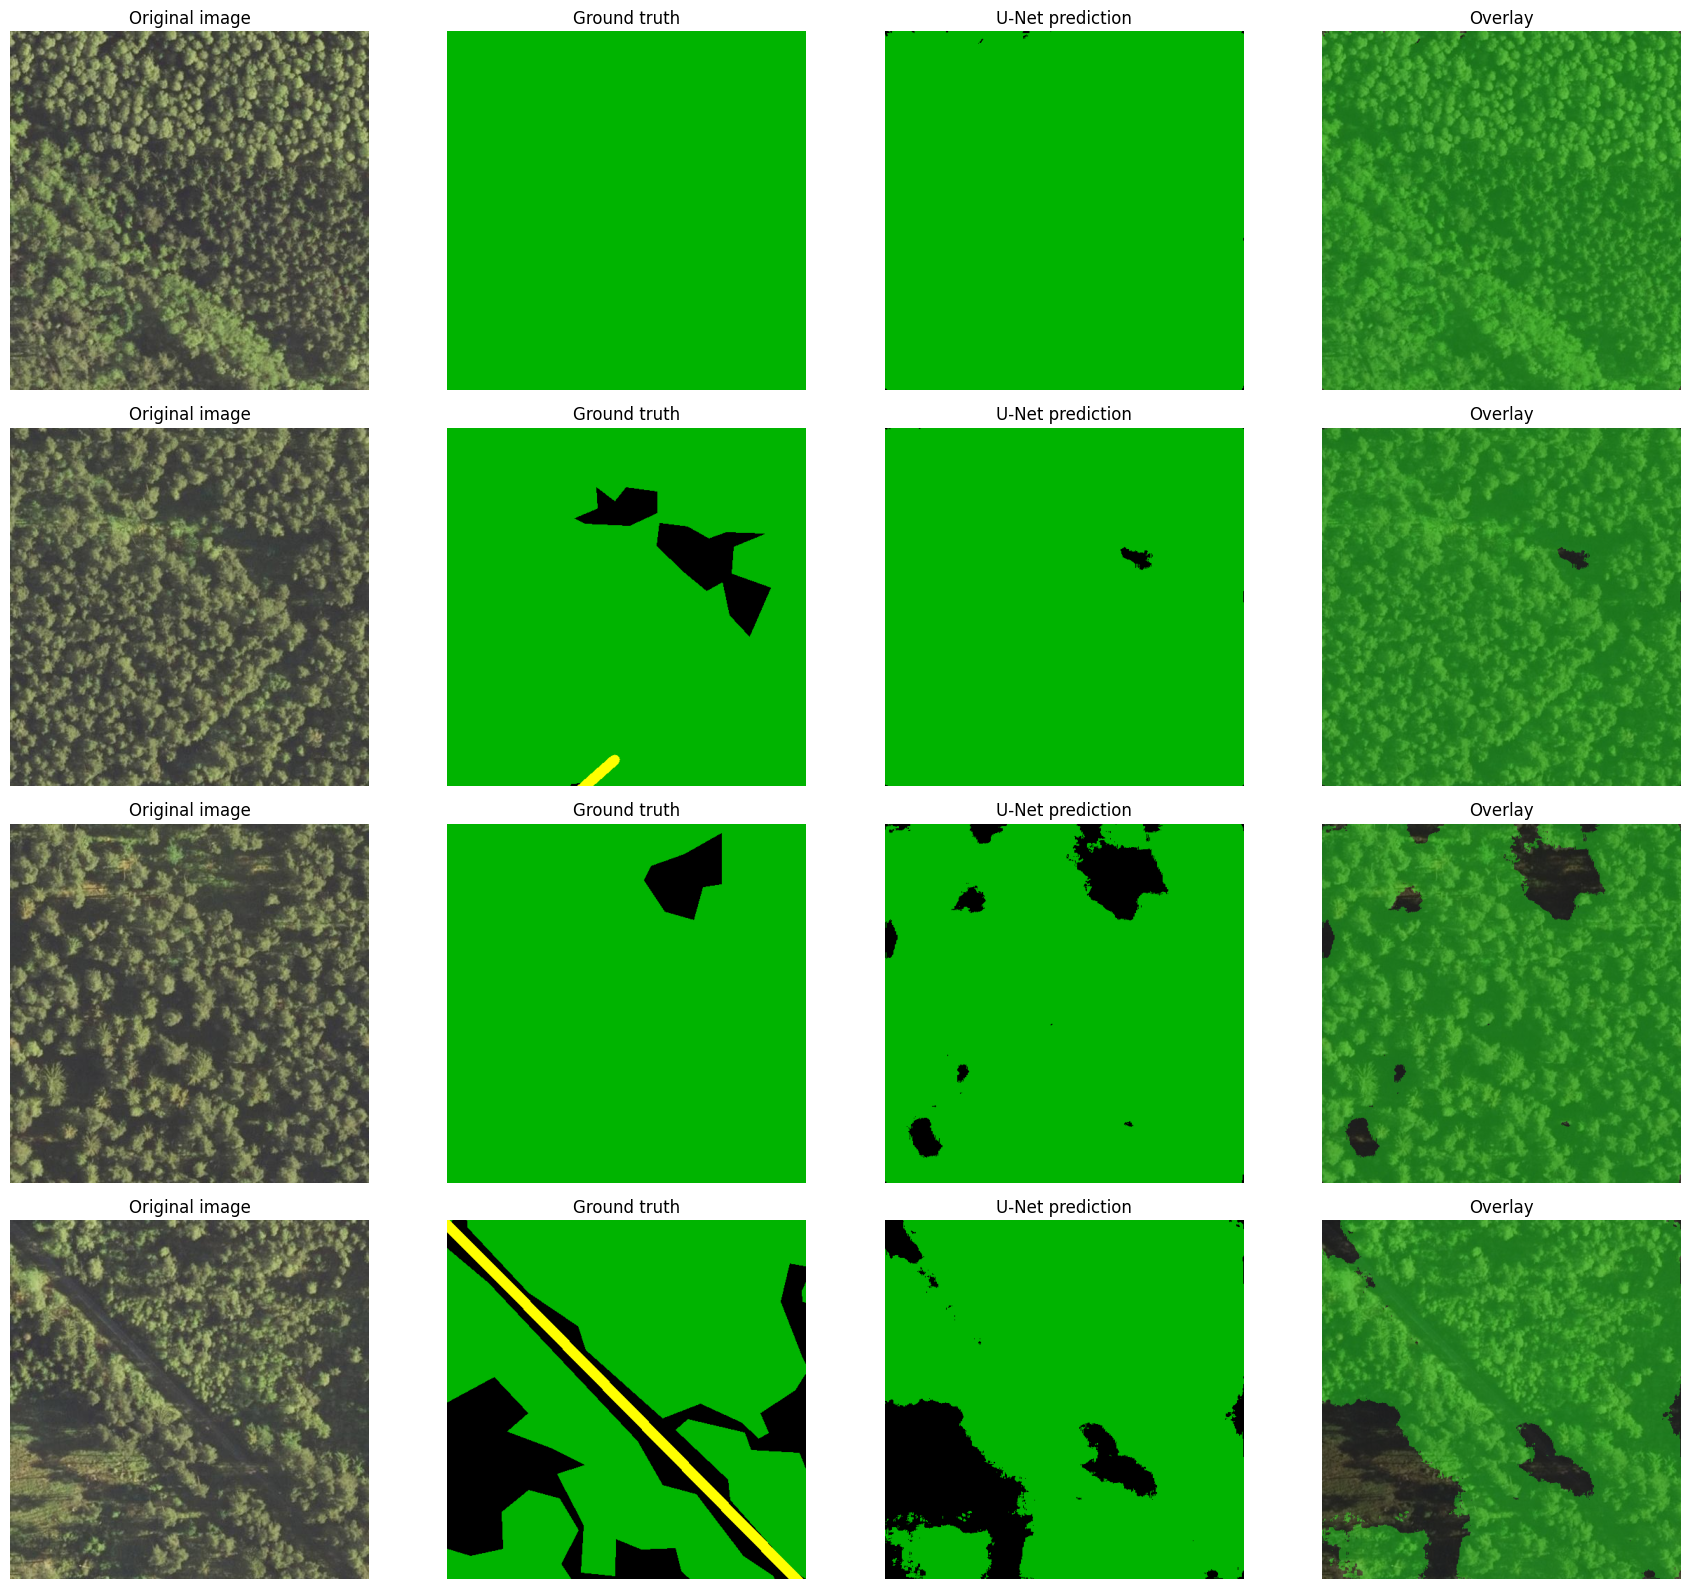

In [65]:

import matplotlib.pyplot as plt
import numpy as np
import torch

class_colors = np.array([
    [0, 0, 0],       # Background
    [255, 0, 0],     # Building
    [0, 180, 0],     # Woodland
    [0, 0, 255],     # Water
    [255, 255, 0]    # Road
])

class_names = [
    "Background", "Building", "Woodland", "Water", "Road"
]

model.eval()

images, masks = next(iter(test_loader))
images_gpu = images.to(device)

with torch.no_grad():
    outputs = model(images_gpu)
    predictions = torch.argmax(outputs, dim=1).cpu().numpy()

images = images.cpu().numpy()
masks = masks.numpy()

fig, axes = plt.subplots(4, 4, figsize=(18, 16))

for i in range(4):

    original = np.transpose(images[i], (1, 2, 0))
    original = np.clip(original, 0, 1)

    real_mask = class_colors[masks[i]]
    predicted_mask = class_colors[predictions[i]]

    overlay = (
        0.5 * original +
        0.5 * (predicted_mask / 255.0)
    )

    axes[i, 0].imshow(original)
    axes[i, 0].set_title("Original image")

    axes[i, 1].imshow(real_mask)
    axes[i, 1].set_title("Ground truth")

    axes[i, 2].imshow(predicted_mask)
    axes[i, 2].set_title("U-Net prediction")

    axes[i, 3].imshow(np.clip(overlay, 0, 1))
    axes[i, 3].set_title("Overlay")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.savefig(
    "/kaggle/working/unet_test_predictions.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
